In [1]:
import io
import yfinance as yf
import requests
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import pickle
from datetime import datetime


In [2]:
def time_elapsed(start_time, end_time):
    if not isinstance(start_time, datetime) or not isinstance(end_time, datetime):
        return None
    elapsed_time = end_time - start_time
    return elapsed_time.days  # Return the number of days

In [3]:
# Official NSE cash-market equity symbols, mapped to Yahoo Finance tickers.
NSE_EQUITY_LIST_URL = 'https://archives.nseindia.com/content/equities/EQUITY_L.csv'
NSE_SERIES = {'EQ', 'BE', 'BZ'}
NSE_DOWNLOAD_BATCH_SIZE = 100
NSE_MAX_TICKERS = None  # Set a positive number for a small test run.
NSE_PLOT_LIMIT = 20
FUNDAMENTALS_TICKERS = []  # Optional .NS tickers; empty avoids thousands of profile requests.
response = requests.get(NSE_EQUITY_LIST_URL, headers={'User-Agent': 'Mozilla/5.0'}, timeout=30)
response.raise_for_status()
nse_universe = pd.read_csv(io.BytesIO(response.content))
nse_universe.columns = [str(column).strip() for column in nse_universe.columns]
required_columns = {'SYMBOL', 'NAME OF COMPANY', 'SERIES'}
missing_columns = required_columns.difference(nse_universe.columns)
if missing_columns:
    raise ValueError(f'NSE equity list is missing required columns: {sorted(missing_columns)}')
nse_universe['SYMBOL'] = nse_universe['SYMBOL'].astype(str).str.strip()
nse_universe['SERIES'] = nse_universe['SERIES'].astype(str).str.strip()
nse_universe = nse_universe[
    nse_universe['SERIES'].isin(NSE_SERIES) & nse_universe['SYMBOL'].ne('')
].drop_duplicates('SYMBOL').sort_values('SYMBOL').reset_index(drop=True)
if NSE_MAX_TICKERS is not None:
    if NSE_MAX_TICKERS <= 0:
        raise ValueError('NSE_MAX_TICKERS must be positive or None')
    nse_universe = nse_universe.head(NSE_MAX_TICKERS)
nse_universe['YAHOO_TICKER'] = nse_universe['SYMBOL'] + '.NS'
stock_ticker = nse_universe['YAHOO_TICKER'].tolist()
nse_company_names = dict(zip(nse_universe['YAHOO_TICKER'], nse_universe['NAME OF COMPANY']))
print(f'NSE symbols selected: {len(stock_ticker)} (series: {", ".join(sorted(NSE_SERIES))})')


NSE symbols selected: 2645 (series: BE, BZ, EQ)


In [4]:
# Batch downloads keep requests manageable for the full NSE universe.
price_frames, download_failures = [], []
for batch_start in range(0, len(stock_ticker), NSE_DOWNLOAD_BATCH_SIZE):
    ticker_batch = stock_ticker[batch_start:batch_start + NSE_DOWNLOAD_BATCH_SIZE]
    try:
        batch_data = yf.download(tickers=ticker_batch, start='2009-01-01', auto_adjust=False,
                                 progress=False, threads=5, group_by='column')
    except Exception as exc:
        download_failures.append((ticker_batch, str(exc)))
        print(f'Batch {batch_start // NSE_DOWNLOAD_BATCH_SIZE + 1} failed: {exc}')
        continue
    if batch_data is None or batch_data.empty:
        download_failures.append((ticker_batch, 'No price data returned'))
        print(f'Batch {batch_start // NSE_DOWNLOAD_BATCH_SIZE + 1} returned no data')
        continue
    if isinstance(batch_data.columns, pd.MultiIndex):
        if 'Close' in batch_data.columns.get_level_values(0):
            pass
        elif 'Close' in batch_data.columns.get_level_values(1):
            batch_data = batch_data.swaplevel(axis=1).sort_index(axis=1)
        else:
            download_failures.append((ticker_batch, 'Close prices missing'))
            print(f'Batch {batch_start // NSE_DOWNLOAD_BATCH_SIZE + 1} has no Close column')
            continue
    elif len(ticker_batch) == 1:
        batch_data.columns = pd.MultiIndex.from_product([batch_data.columns, ticker_batch])
    else:
        download_failures.append((ticker_batch, 'Unexpected single-level columns'))
        print(f'Batch {batch_start // NSE_DOWNLOAD_BATCH_SIZE + 1} has unexpected columns')
        continue
    close_data = batch_data.loc[:, batch_data.columns.get_level_values(0) == 'Close']
    if close_data.empty:
        download_failures.append((ticker_batch, 'No Close price data returned'))
        print(f'Batch {batch_start // NSE_DOWNLOAD_BATCH_SIZE + 1} has no Close price data')
        continue
    price_frames.append(close_data)
if not price_frames:
    raise RuntimeError('No NSE price history downloaded; check network and yfinance availability.')
stock_name = pd.concat(price_frames, axis=1)
stock_name = stock_name.loc[:, ~stock_name.columns.duplicated()]
stock_ticker = [t for t in stock_ticker if ('Close', t) in stock_name.columns and stock_name[('Close', t)].notna().any()]
if not stock_ticker:
    raise RuntimeError('No listed NSE symbol has usable Yahoo Close price history.')
nse_company_names = {t: nse_company_names[t] for t in stock_ticker}
stock_info = {t: {'longName': name} for t, name in nse_company_names.items()}
print(f'Price history available for {len(stock_ticker)} of {len(nse_universe)} selected symbols.')
print(f'Failed/empty download batches: {len(download_failures)}')


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inpla

Price history available for 2644 of 2645 selected symbols.
Failed/empty download batches: 0


In [5]:
print(f'Downloaded {stock_name.shape[0]} trading dates for {len(stock_ticker)} symbols.')
display(stock_name.iloc[-5:, :min(12, stock_name.shape[1])])


Downloaded 4408 trading dates for 2644 symbols.


Price             Close                                                        \
Ticker     20MICRONS.NS 21STCENMGM.NS    360ONE.NS 3BBLACKBIO.NS 3IINFOLTD.NS   
Date                                                                            
2026-11-04   181.070007     60.560001  1068.699951   1331.500000    19.129999   
2026-11-05   180.259995     57.540001  1140.900024   1309.099976    19.070000   
2026-11-06   183.220001     54.669998  1145.000000   1284.199951    18.840000   
2026-11-08          NaN           NaN          NaN           NaN          NaN   
2026-11-09   187.330002     54.529999  1138.000000   1293.599976    19.230000   

Price                                                                 \
Ticker     3MINDIA.NS  3PLAND.NS   5PAISA.NS  63MOONS.NS A2ZINFRA.NS   
Date                                                                   
2026-11-04    28835.0  30.969999  325.950012  925.950012       13.00   
2026-11-05    29325.0  30.510000  339.899994  951.849976       13.09   
2026-11-06    27570.0  31.950001  339.100006  896.000000       13.09   
2026-11-08        NaN        NaN         NaN         NaN         NaN   
2026-11-09    28070.0  31.500000  351.399994  898.700012       13.74   

Price                                
Ticker      AAATECH.NS AADHARHFC.NS  
Date                                 
2026-11-04  103.570000   431.200012  
2026-11-05  102.720001   438.250000  
2026-11-06   96.400002   429.649994  
2026-11-08         NaN          NaN  
2026-11-09   91.699997   433.350006

In [6]:
simulation_ticker = stock_ticker[0] if isinstance(stock_ticker, (list, tuple)) else stock_ticker
close_prices = stock_name[('Close', simulation_ticker)].dropna()

In [7]:
display(close_prices)

Date
2009-01-02      9.100000
2009-01-05      9.125000
2009-01-06      8.975000
2009-01-07      8.000000
2009-01-09      7.525000
                 ...    
2026-11-03    174.830002
2026-11-04    181.070007
2026-11-05    180.259995
2026-11-06    183.220001
2026-11-09    187.330002
Name: (Close, 20MICRONS.NS), Length: 4403, dtype: float64

In [8]:
# Total growth = last price / first price
total_growth = close_prices.iloc[-1] / close_prices.iloc[0]

In [9]:
print(total_growth)

20.585713623981114


In [10]:
# Current price / first record (e.g., price at the beginning of 2009)
# provides us with the total growth %

# Next, we want to annualize this percentage
# First, we convert our time elapsed to the number of years elapsed
number_of_days = time_elapsed(stock_name.index[0], stock_name.index[-1])
number_of_years = number_of_days / 365.0  # Assuming 365 days per year

In [11]:
print(number_of_days)
print(number_of_years)

6520
17.863013698630137


In [12]:
print(stock_name.index[0])
print(stock_name.index[-1])

2009-01-02 00:00:00
2026-11-09 00:00:00


In [13]:
simulation_ticker = stock_ticker[0]
close_prices = stock_name[('Close', simulation_ticker)].dropna()
elapsed_years = (close_prices.index[-1] - close_prices.index[0]).days / 365.25
if close_prices.empty or elapsed_years <= 0:
    raise ValueError(f'Cannot calculate historical growth for {simulation_ticker}: insufficient history')
cagr = (close_prices.iloc[-1] / close_prices.iloc[0]) ** (1 / elapsed_years) - 1
std_dev = close_prices.pct_change().std() * math.sqrt(252)
if not np.isfinite(cagr) or not np.isfinite(std_dev):
    raise ValueError(f'Cannot simulate {simulation_ticker}: invalid price history')
number_of_trading_days = 252
daily_return_percentages = np.random.normal(cagr / 252, std_dev / math.sqrt(252), 252) + 1
price_series = [float(close_prices.iloc[-1])]
for daily_return in daily_return_percentages:
    price_series.append(price_series[-1] * daily_return)


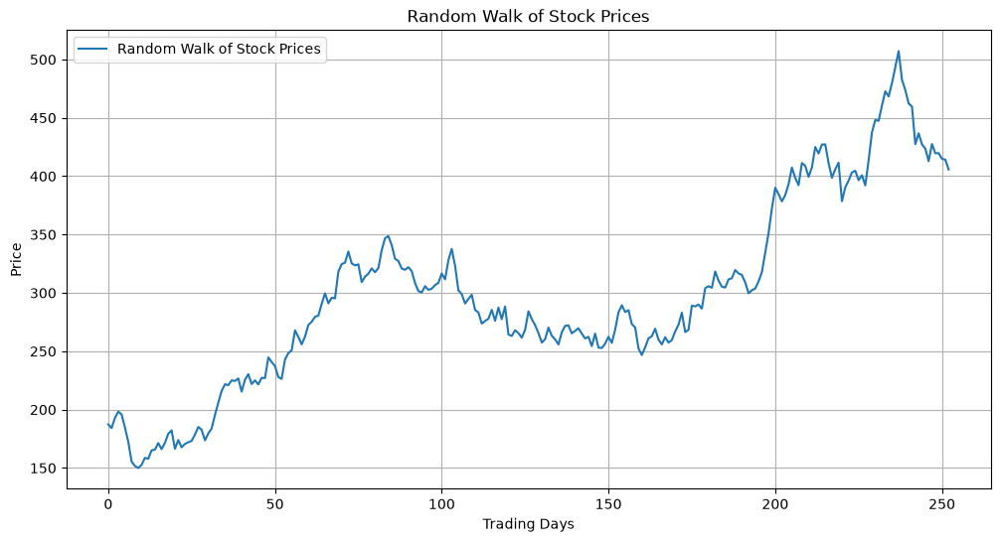

In [14]:
# Plot a single 'random walk' of stock prices
plt.figure(figsize=(12, 6))
plt.plot(price_series, label='Random Walk of Stock Prices')
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walk of Stock Prices')
plt.legend()
plt.grid(True)
plt.show()

# Now that we've created a single random walk above,
# we can simulate this process over a large sample size to
# get a better sense of the true expected distribution
number_of_trials = 3000

# Set up an additional array to collect all possible
# closing prices on the last day of the window.
# We can use this for a histogram to get a clearer sense of possible outcomes
closing_prices = []


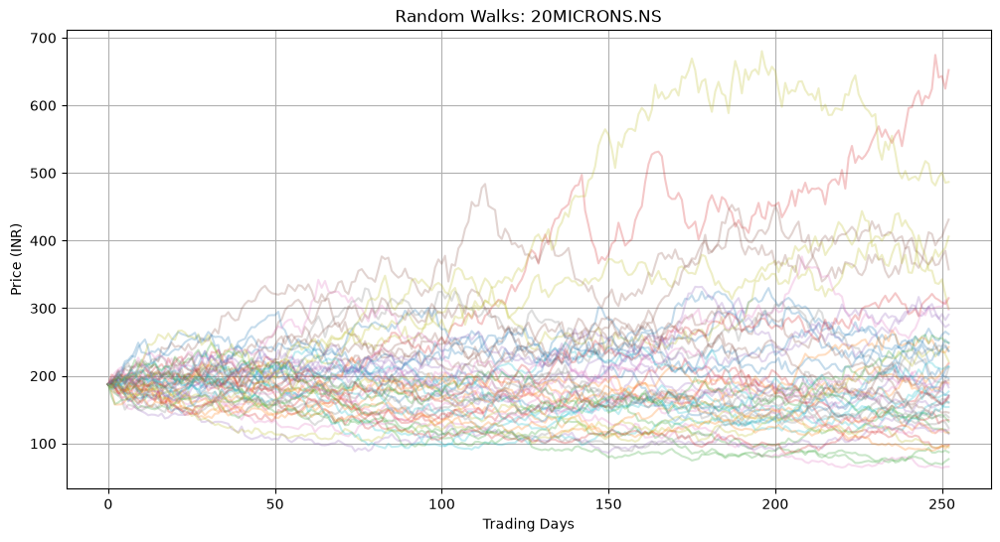

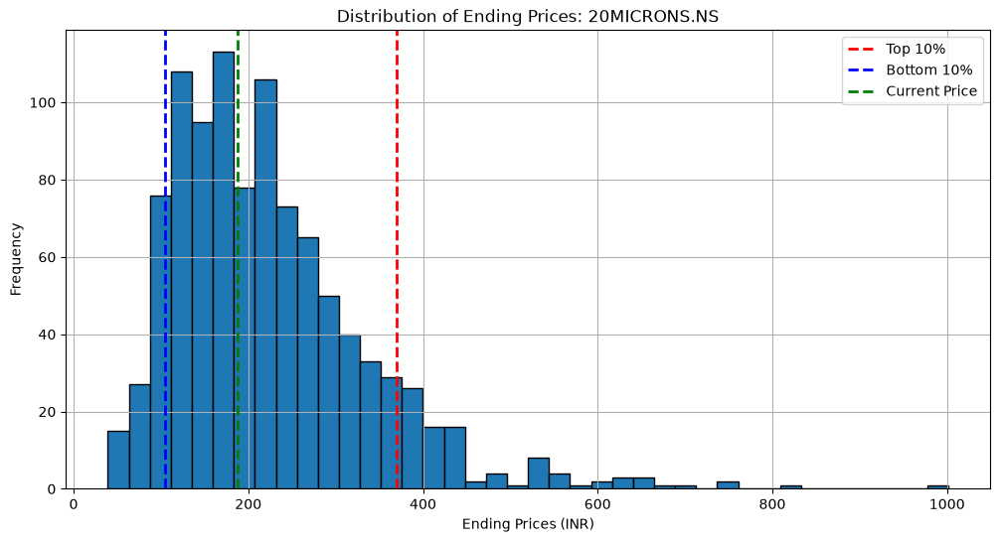

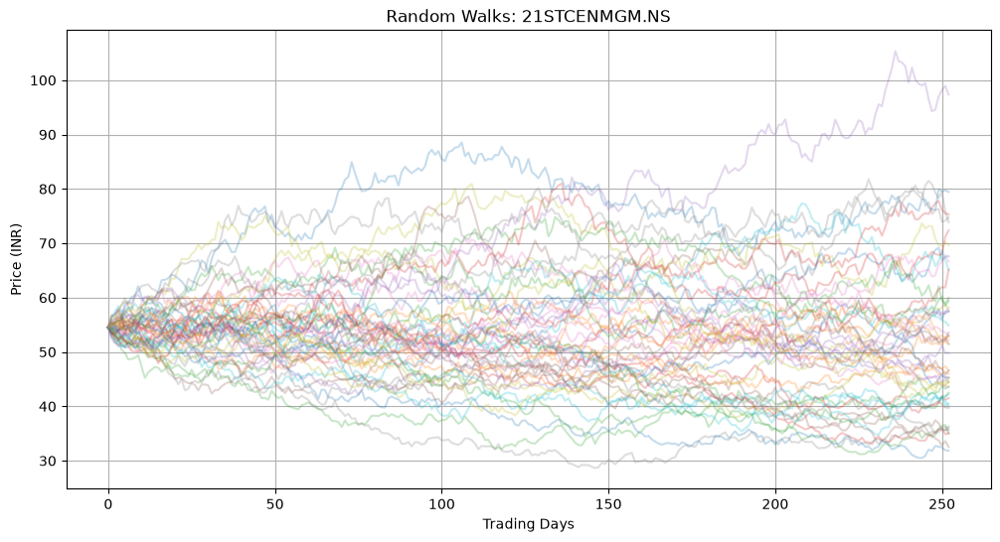

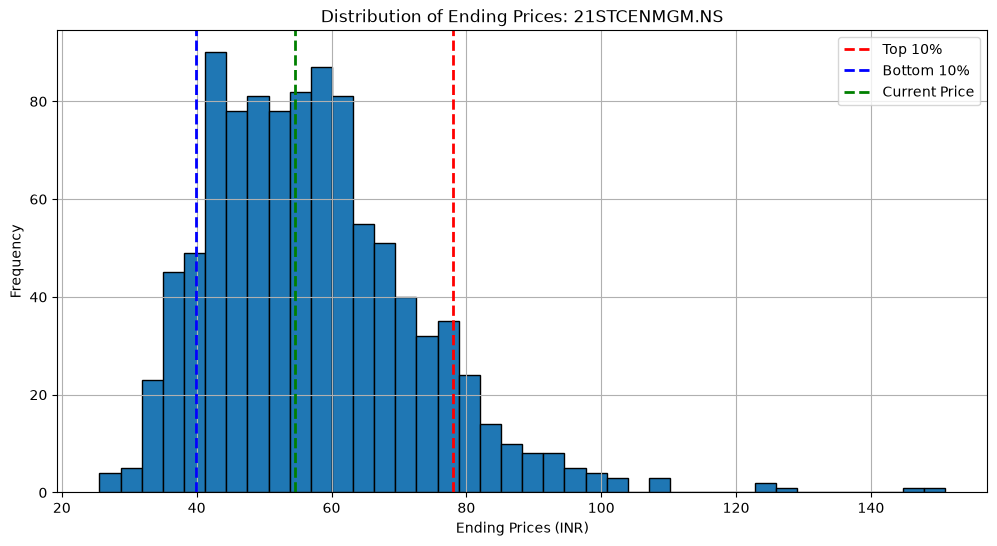

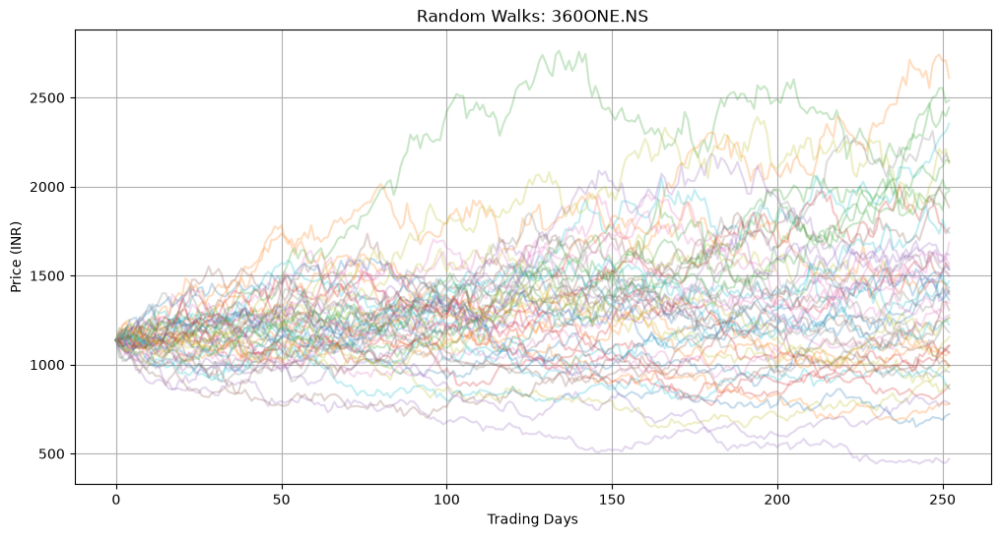

...

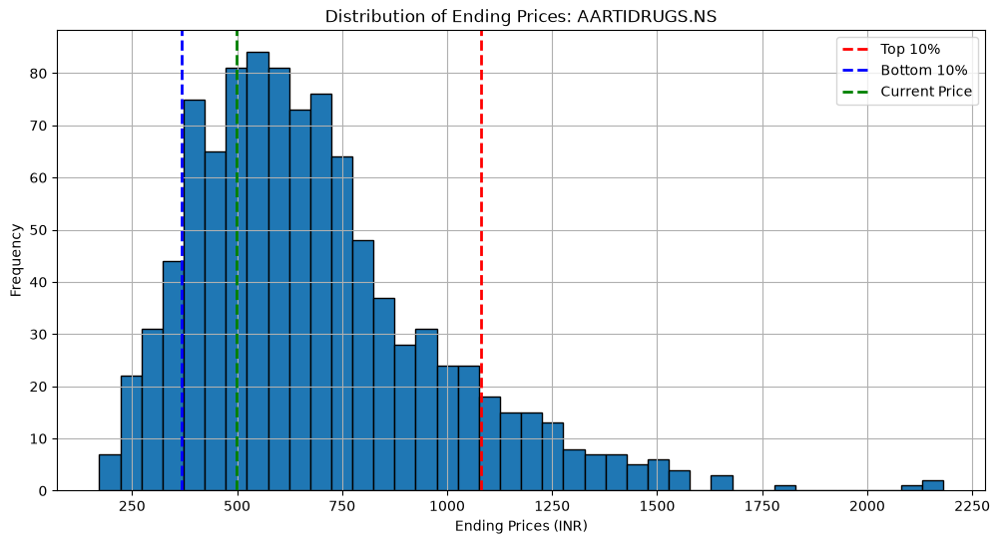

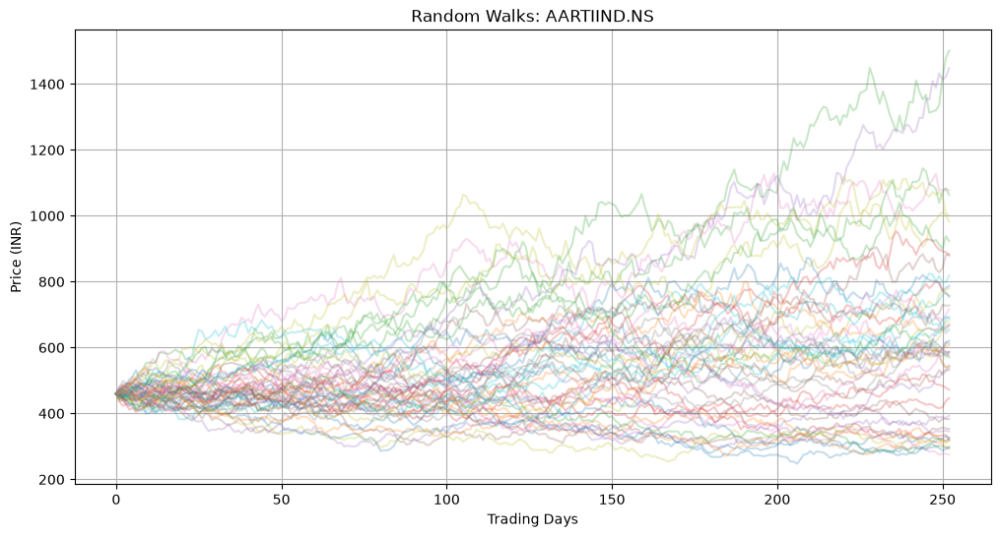

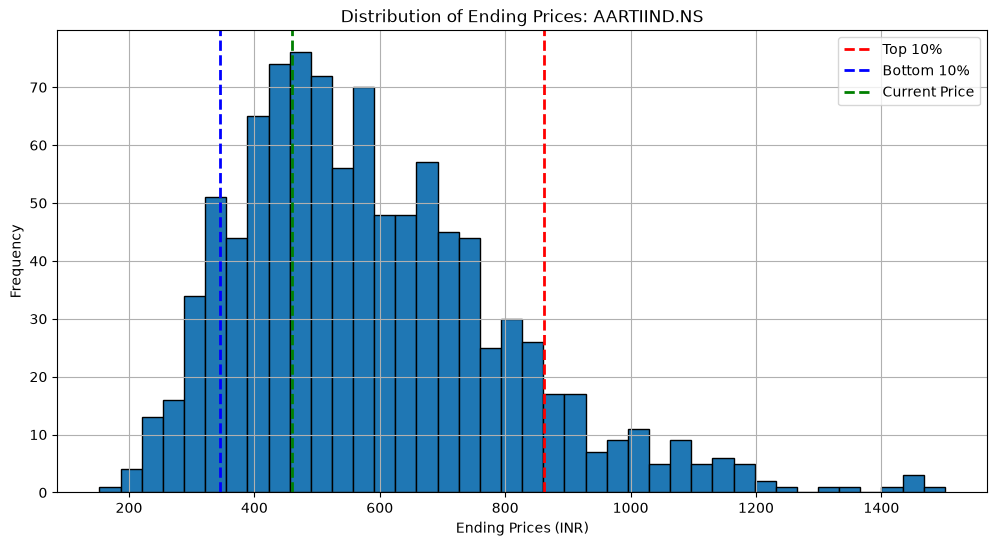

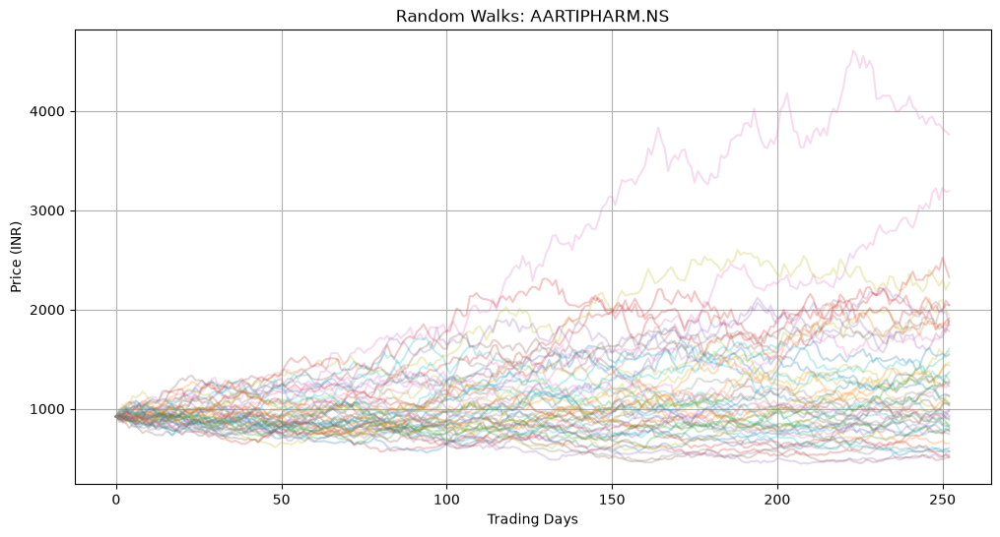

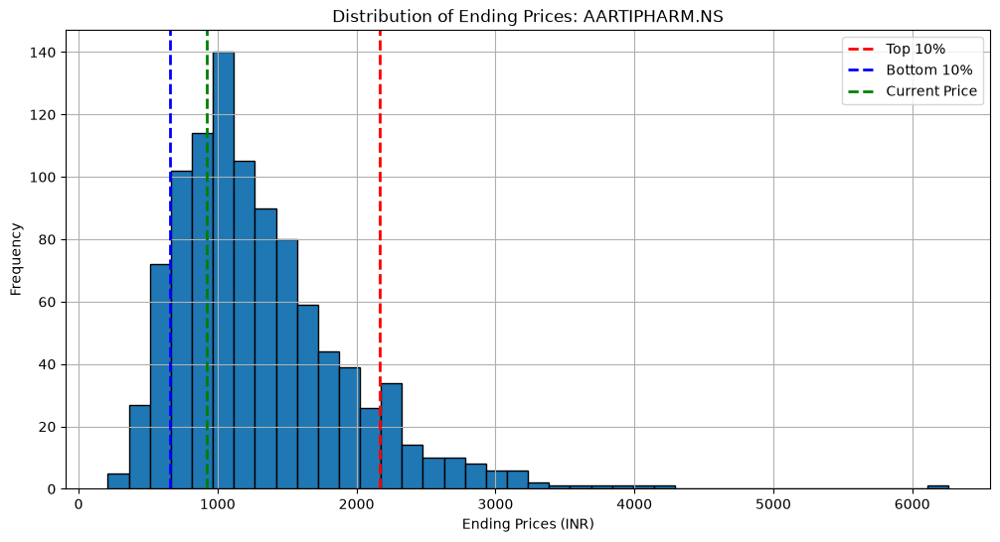

Basic simulations completed: 2355 of 2644 downloaded symbols.
Skipped for insufficient/invalid data: 289


In [15]:
number_of_trials = 1000
number_of_trading_days = 252
minimum_history_days = 60
plot_tickers = set(stock_ticker[:NSE_PLOT_LIMIT])
simulation_results, skipped_tickers = {}, []
for ticker in stock_ticker:
    series = stock_name[('Close', ticker)].dropna()
    if len(series) < minimum_history_days:
        skipped_tickers.append((ticker, 'less than 60 historical prices'))
        continue
    elapsed_years = (series.index[-1] - series.index[0]).days / 365.25
    if elapsed_years <= 0:
        skipped_tickers.append((ticker, 'invalid date range'))
        continue
    cagr = (series.iloc[-1] / series.iloc[0]) ** (1 / elapsed_years) - 1
    std_dev = series.pct_change().std() * math.sqrt(number_of_trading_days)
    if not np.isfinite(cagr) or not np.isfinite(std_dev):
        skipped_tickers.append((ticker, 'invalid simulation parameters'))
        continue
    daily_factors = np.random.normal(cagr / 252, std_dev / math.sqrt(252),
                                     size=(number_of_trials, number_of_trading_days)) + 1
    closing = float(series.iloc[-1]) * np.prod(daily_factors, axis=1)
    if not np.isfinite(closing).all():
        skipped_tickers.append((ticker, 'non-finite simulated prices'))
        continue
    current = float(series.iloc[-1])
    simulation_results[ticker] = {
        'closing_prices': closing.tolist(), 'mean_end_price': float(np.mean(closing)),
        'top_ten': float(np.percentile(closing, 90)), 'bottom_ten': float(np.percentile(closing, 10)),
        'current_price': current,
    }
    if ticker in plot_tickers:
        plt.figure(figsize=(12, 6))
        for path in current * np.cumprod(daily_factors[:50], axis=1):
            plt.plot(np.r_[current, path], alpha=0.25)
        plt.title(f'Random Walks: {ticker}')
        plt.xlabel('Trading Days')
        plt.ylabel('Price (INR)')
        plt.grid(True)
        plt.show()
        plt.close()
        plt.figure(figsize=(12, 6))
        plt.hist(closing, bins=40, edgecolor='black')
        plt.axvline(np.percentile(closing, 90), color='r', linestyle='dashed', linewidth=2, label='Top 10%')
        plt.axvline(np.percentile(closing, 10), color='b', linestyle='dashed', linewidth=2, label='Bottom 10%')
        plt.axvline(current, color='g', linestyle='dashed', linewidth=2, label='Current Price')
        plt.xlabel('Ending Prices (INR)')
        plt.ylabel('Frequency')
        plt.title(f'Distribution of Ending Prices: {ticker}')
        plt.legend()
        plt.grid(True)
        plt.savefig(f'histogram_{ticker}.png')
        plt.show()
        plt.close()
closing_prices_by_ticker = {t: result['closing_prices'] for t, result in simulation_results.items()}
if not simulation_results:
    raise RuntimeError('No symbols had enough valid data to simulate.')
print(f'Basic simulations completed: {len(simulation_results)} of {len(stock_ticker)} downloaded symbols.')
print(f'Skipped for insufficient/invalid data: {len(skipped_tickers)}')


In [16]:
data_to_pickle = {
    'universe': stock_ticker,
    'company_names': nse_company_names,
    'simulation_results': simulation_results,
}
pickle_file_path = 'nse_stock_simulation_data.pkl'
with open(pickle_file_path, 'wb') as pickle_file:
    pickle.dump(data_to_pickle, pickle_file)
print(f'Data has been saved to {pickle_file_path}')


Data has been saved to nse_stock_simulation_data.pkl


In [17]:
target_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)
basic_projection_table = pd.DataFrame.from_dict(simulation_results, orient='index')
basic_projection_table.index.name = 'yahoo_ticker'
basic_projection_table['company'] = [nse_company_names[t] for t in basic_projection_table.index]
basic_projection_table['projected_return_pct'] = (basic_projection_table['mean_end_price'] / basic_projection_table['current_price'] - 1) * 100
print('Last available data date:', stock_name.index[-1].date())
print('1-year projection date:', target_date.date())
print(f'Projection results for {len(basic_projection_table)} symbols; displaying the 15 highest projected returns.')
display(basic_projection_table.sort_values('projected_return_pct', ascending=False).head(15))


Last available data date: 2026-11-09
1-year projection date: 2027-10-27
Projection results for 2355 symbols; displaying the 15 highest projected returns.


,closing_prices,mean_end_price,top_ten,bottom_ten,current_price,company,projected_return_pct
yahoo_ticker,,,,,,,
LAKSHMIMIL.NS,[10038271051753091829623319743987276916457472....,4.948847e+47,5.197814e+47,9.748248e+43,8035.000000,Lakshmi Mills Company Limited,6.159113e+45
BATLIBOI.NS,"[1970060.001518, -712354.186643, 10.2137, 3470...",2.113822e+08,2.219726e+06,-8.248377e+01,89.279999,Batliboi Limited,2.367632e+08
XTRANET.NS,"[64174558.272047, 329059562.901234, 45112055.8...",9.929465e+07,1.996236e+08,2.083249e+07,270.649994,Xtranet Technologies Limited,3.668738e+07
VTMLTD.NS,"[35128.393629, 10416.292091, 97359.684477, 363...",2.506092e+05,4.785162e+05,1.177871e+03,40.709999,VTM Limited,6.154961e+05
AMARJOTHI.NS,"[4798.964875, 186036.444009, 2349244.395908, 4...",3.266002e+05,7.605834e+05,8.616129e+03,152.500000,Amarjothi Spinning Mills Limited,2.140641e+05
INDOMIM.NS,"[319643.633815, 827944.610081, 350215.289009, ...",4.481546e+05,7.698846e+05,1.894541e+05,1274.400024,INDO-MIM Limited,3.506592e+04
RAMBHAJO.NS,"[49388.34086, 13380.264678, 18626.474526, 1776...",2.196623e+04,4.199824e+04,6.406054e+03,325.649994,Advit Jewels Limited,6.645350e+03
RAJPALAYAM.NS,"[21922.243946, 29947.474753, 190265.165469, 55...",3.284486e+04,4.450424e+04,2.074617e+02,751.200012,Rajapalayam Mills Limited,4.272319e+03
OMNI.NS,"[7793.066266, 8691.909706, 6895.494956, 4377.1...",1.712690e+04,3.362136e+04,5.095508e+03,567.950012,Omnitech Engineering Limited,2.915565e+03


# NSE-wide Monte Carlo projections with optional analyst enrichment

The universe comes from the official NSE equity list (`EQ`, `BE`, and `BZ` series), mapped to Yahoo Finance `.NS` symbols. Every symbol with usable Yahoo price history is simulated; symbols without data or at least 60 price observations are skipped and counted.

Historical price data drives both models. Analyst targets and fundamentals are fetched only for symbols explicitly listed in `FUNDAMENTALS_TICKERS` in the setup cell, avoiding thousands of rate-limited profile requests. Without analyst data, enhanced drift falls back to historical CAGR.

Plots are limited to `NSE_PLOT_LIMIT` symbols by default. Set `NSE_MAX_TICKERS` for a smaller test run.


In [18]:
# Find technical-screen candidates first, then request analyst targets only for those symbols.
def build_positive_momentum_rows():
    rows = []
    for ticker_symbol in stock_ticker:
        close_series = stock_name[('Close', ticker_symbol)].dropna().sort_index()
        if len(close_series) < 50:
            continue

        latest_date = close_series.index[-1]
        year_start = pd.Timestamp(year=latest_date.year, month=1, day=1, tz=latest_date.tz)
        three_month_start = latest_date - pd.DateOffset(months=3)
        prior_year_close = close_series.loc[close_series.index < year_start]
        if prior_year_close.empty:
            year_to_date_prices = close_series.loc[close_series.index >= year_start]
            if year_to_date_prices.empty:
                continue
            ytd_start_price = float(year_to_date_prices.iloc[0])
        else:
            ytd_start_price = float(prior_year_close.iloc[-1])

        three_month_prices = close_series.loc[close_series.index <= three_month_start]
        if three_month_prices.empty or ytd_start_price <= 0:
            continue
        three_month_start_price = float(three_month_prices.iloc[-1])
        current_price = float(close_series.iloc[-1])
        if three_month_start_price <= 0:
            continue

        ema_9 = close_series.ewm(span=9, adjust=False, min_periods=9).mean().iloc[-1]
        ema_20 = close_series.ewm(span=20, adjust=False, min_periods=20).mean().iloc[-1]
        ema_50 = close_series.ewm(span=50, adjust=False, min_periods=50).mean().iloc[-1]
        ytd_return = current_price / ytd_start_price - 1
        three_month_return = current_price / three_month_start_price - 1

        if ytd_return > 0 and three_month_return > 0 and ema_9 > ema_20 > ema_50:
            nse_symbol = ticker_symbol[:-3] if ticker_symbol.endswith('.NS') else ticker_symbol
            rows.append({
                'yahoo_ticker': ticker_symbol,
                'nse_symbol': nse_symbol,
                'company': nse_company_names.get(ticker_symbol, nse_symbol),
                'as_of': latest_date.date(),
                'current_price': current_price,
                'ytd_return_pct': ytd_return * 100,
                'three_month_return_pct': three_month_return * 100,
                'ema_9': float(ema_9),
                'ema_20': float(ema_20),
                'ema_50': float(ema_50),
            })
    return rows

positive_momentum_rows = build_positive_momentum_rows()
positive_momentum_tickers = [row['yahoo_ticker'] for row in positive_momentum_rows]
selected_fundamentals_tickers = [t for t in FUNDAMENTALS_TICKERS if t in stock_ticker]
analyst_target_tickers = sorted(set(selected_fundamentals_tickers) | set(positive_momentum_tickers))
fundamentals_by_ticker = {t: {} for t in stock_ticker}
for ticker_symbol in analyst_target_tickers:
    try:
        info = yf.Ticker(ticker_symbol).info
        fundamentals_by_ticker[ticker_symbol] = {
            key: info.get(key) for key in (
                'currentPrice', 'targetMeanPrice', 'targetMedianPrice', 'targetHighPrice',
                'targetLowPrice', 'recommendationKey', 'numberOfAnalystOpinions',
                'trailingPE', 'forwardPE', 'trailingEps', 'forwardEps', 'earningsGrowth',
                'revenueGrowth', 'beta', 'marketCap',
            )
        }
        print(f'Fetched profile and analyst data for {ticker_symbol}')
    except Exception as exc:
        print(f'Could not fetch fundamentals for {ticker_symbol}: {exc}')
print(f'Fundamentals fetched for {sum(bool(v) for v in fundamentals_by_ticker.values())} symbols.')
print(f'Analyst target lookup requested for {len(analyst_target_tickers)} symbols, including {len(positive_momentum_tickers)} momentum-screen candidates.')
fundamentals = fundamentals_by_ticker


Fetched profile and analyst data for 21STCENMGM.NS
Fetched profile and analyst data for 63MOONS.NS
Fetched profile and analyst data for AAREYDRUGS.NS
Fetched profile and analyst data for AARTIDRUGS.NS
Fetched profile and analyst data for AARTIPHARM.NS
Fetched profile and analyst data for ABDL.NS
Fetched profile and analyst data for ACUTAAS.NS
Fetched profile and analyst data for ADANIGREEN.NS
Fetched profile and analyst data for ADANIPORTS.NS
Fetched profile and analyst data for ADROITINFO.NS
Fetched profile and analyst data for AEROPLANE.NS
Fetched profile and analyst data for AFFORDABLE.NS
Fetched profile and analyst data for AHCL.NS
Fetched profile and analyst data for AIROLAM.NS
Fetched profile and analyst data for ALGOQUANT.NS
Fetched profile and analyst data for ALICON.NS
Fetched profile and analyst data for ALIVUS.NS
Fetched profile and analyst data for AMANTA.NS
Fetched profile and analyst data for ANANDRATHI.NS
Fetched profile and analyst data for ANGELONE.NS
Fetched profile a

In [19]:
eps_trends, growth_estimates_by_ticker = {}, {}
for ticker_symbol in selected_fundamentals_tickers:
    ticker = yf.Ticker(ticker_symbol)
    try:
        eps_trends[ticker_symbol] = ticker.eps_trend
        display(eps_trends[ticker_symbol])
    except Exception as exc:
        print(f'EPS trend unavailable for {ticker_symbol}: {exc}')
        eps_trends[ticker_symbol] = None
    try:
        growth_estimates_by_ticker[ticker_symbol] = ticker.growth_estimates
        display(growth_estimates_by_ticker[ticker_symbol])
    except Exception as exc:
        print(f'Growth estimates unavailable for {ticker_symbol}: {exc}')
        growth_estimates_by_ticker[ticker_symbol] = None
if not selected_fundamentals_tickers:
    print('EPS/growth API calls skipped; add .NS symbols to FUNDAMENTALS_TICKERS to enable them.')


EPS/growth API calls skipped; add .NS symbols to FUNDAMENTALS_TICKERS to enable them.


In [20]:
stock_metrics = {}
for ticker_symbol in stock_ticker:
    close_series = stock_name[('Close', ticker_symbol)].dropna()
    if len(close_series) < minimum_history_days:
        continue
    elapsed_years = (close_series.index[-1] - close_series.index[0]).days / 365.25
    if elapsed_years <= 0:
        continue
    current_price = float(close_series.iloc[-1])
    ticker_cagr = (close_series.iloc[-1] / close_series.iloc[0]) ** (1 / elapsed_years) - 1
    ticker_std_dev = close_series.pct_change().std() * math.sqrt(252)
    recent_std_dev = close_series.tail(504).pct_change().std() * math.sqrt(252)
    if not np.isfinite(recent_std_dev):
        recent_std_dev = ticker_std_dev
    if not np.isfinite(ticker_cagr) or not np.isfinite(ticker_std_dev):
        continue
    analyst_target = fundamentals_by_ticker.get(ticker_symbol, {}).get('targetMeanPrice')
    try:
        analyst_target = float(analyst_target) if analyst_target is not None else None
    except (TypeError, ValueError):
        analyst_target = None
    if analyst_target is not None and (not np.isfinite(analyst_target) or analyst_target <= 0):
        analyst_target = None
    analyst_return = analyst_target / current_price - 1 if analyst_target is not None and current_price > 0 else None
    blended_drift = 0.5 * (ticker_cagr + analyst_return) if analyst_return is not None else ticker_cagr
    stock_metrics[ticker_symbol] = {
        'current_price': current_price, 'cagr': ticker_cagr,
        'analyst_mean_1y': analyst_target, 'analyst_implied_return': analyst_return,
        'blended_drift': blended_drift, 'long_term_volatility': ticker_std_dev,
        'recent_volatility': recent_std_dev,
        'blended_volatility': 0.5 * ticker_std_dev + 0.5 * recent_std_dev,
    }
print(f'Enhanced metrics calculated for {len(stock_metrics)} symbols.')
print(f'Analyst targets available for {sum(m["analyst_mean_1y"] is not None for m in stock_metrics.values())} symbols.')


Enhanced metrics calculated for 2356 symbols.
Analyst targets available for 142 symbols.


In [21]:
enhanced_simulation_results = {}
for ticker_symbol, metrics in stock_metrics.items():
    daily_factors = np.random.normal(
        metrics['blended_drift'] / number_of_trading_days,
        metrics['blended_volatility'] / math.sqrt(number_of_trading_days),
        size=(number_of_trials, number_of_trading_days),
    ) + 1
    closing = metrics['current_price'] * np.prod(daily_factors, axis=1)
    if not np.isfinite(closing).all():
        print(f'Skipping enhanced simulation for {ticker_symbol}: non-finite prices')
        continue
    enhanced_simulation_results[ticker_symbol] = closing.tolist()
if not enhanced_simulation_results:
    raise RuntimeError('No valid enhanced NSE simulations were produced.')
print(f'Enhanced simulations completed for {len(enhanced_simulation_results)} symbols.')


Skipping enhanced simulation for SEJALLTD.NS: non-finite prices
Enhanced simulations completed for 2355 symbols.


In [22]:
enhanced_projection_summary = {}
projection_date = stock_name.index[-1] + pd.tseries.offsets.BDay(number_of_trading_days)
for ticker_symbol, closing in enhanced_simulation_results.items():
    metrics = stock_metrics[ticker_symbol]
    current_price = metrics['current_price']
    enhanced_projection_summary[ticker_symbol] = {
        'current_price': current_price, 'mean_price': float(np.mean(closing)),
        'p5': float(np.percentile(closing, 5)), 'p25': float(np.percentile(closing, 25)),
        'p50': float(np.percentile(closing, 50)), 'p75': float(np.percentile(closing, 75)),
        'p95': float(np.percentile(closing, 95)),
        'prob_gain': float(np.mean(np.asarray(closing) > current_price)),
        'projection_date': projection_date, 'analyst_mean_1y': metrics['analyst_mean_1y'],
    }
enhanced_projection_table = pd.DataFrame.from_dict(enhanced_projection_summary, orient='index')
enhanced_projection_table.index.name = 'yahoo_ticker'
enhanced_projection_table['nse_symbol'] = [t.removesuffix('.NS') for t in enhanced_projection_table.index]
enhanced_projection_table['company'] = [nse_company_names.get(t, t) for t in enhanced_projection_table.index]
enhanced_projection_table['projected_return_pct'] = (enhanced_projection_table['mean_price'] / enhanced_projection_table['current_price'] - 1) * 100
print(f'One-year projections completed for {len(enhanced_projection_table)} symbols.')
display(enhanced_projection_table.sort_values('projected_return_pct', ascending=False).head(20))


One-year projections completed for 2355 symbols.


,current_price,mean_price,p5,p25,p50,p75,p95,prob_gain,projection_date,analyst_mean_1y,nse_symbol,company,projected_return_pct
yahoo_ticker,,,,,,,,,,,,,
CYBERTECH.NS,124.790001,1.291829e+72,-1.143996e+61,-2.009533e+52,-7.938465e+34,1.336289e+52,1.163924e+62,0.496,2027-10-27,NaN,CYBERTECH,Cybertech Systems And Software Limited,1.035202e+72
MELSTAR.NS,421.160004,4.776472e+56,-8.733280e+47,-5.158782e+37,6.412592e+24,4.152384e+38,5.715996e+47,0.510,2027-10-27,NaN,MELSTAR,Melstar Information Technologies Limited,1.134123e+56
LAKSHMIMIL.NS,8035.000000,9.153938e+47,3.895559e+43,9.922618e+44,7.357582e+45,7.751285e+46,1.912498e+48,1.000,2027-10-27,NaN,LAKSHMIMIL,Lakshmi Mills Company Limited,1.139258e+46
BATLIBOI.NS,89.279999,4.401783e+08,-6.113744e+03,2.565620e-03,7.888695e+01,2.929168e+04,2.554317e+07,0.490,2027-10-27,NaN,BATLIBOI,Batliboi Limited,4.930312e+08
XTRANET.NS,270.649994,9.595976e+07,1.332806e+07,3.357517e+07,6.037922e+07,1.191355e+08,2.773624e+08,1.000,2027-10-27,NaN,XTRANET,Xtranet Technologies Limited,3.545520e+07
VTMLTD.NS,40.709999,1.920338e+05,5.190972e+02,4.754351e+03,2.201823e+04,9.628592e+04,7.954814e+05,0.997,2027-10-27,NaN,VTMLTD,VTM Limited,4.716117e+05
AMARJOTHI.NS,152.500000,3.757333e+05,4.957364e+03,2.833149e+04,9.683326e+04,2.865482e+05,1.531954e+06,1.000,2027-10-27,NaN,AMARJOTHI,Amarjothi Spinning Mills Limited,2.462825e+05
RAMBHAJO.NS,325.649994,2.228095e+04,4.896707e+03,1.001374e+04,1.664858e+04,2.826659e+04,5.776051e+04,1.000,2027-10-27,NaN,RAMBHAJO,Advit Jewels Limited,6.741993e+03
RAJPALAYAM.NS,751.200012,2.707358e+04,9.520045e+01,7.860175e+02,3.273956e+03,1.417541e+04,1.035797e+05,0.760,2027-10-27,NaN,RAJPALAYAM,Rajapalayam Mills Limited,3.504044e+03


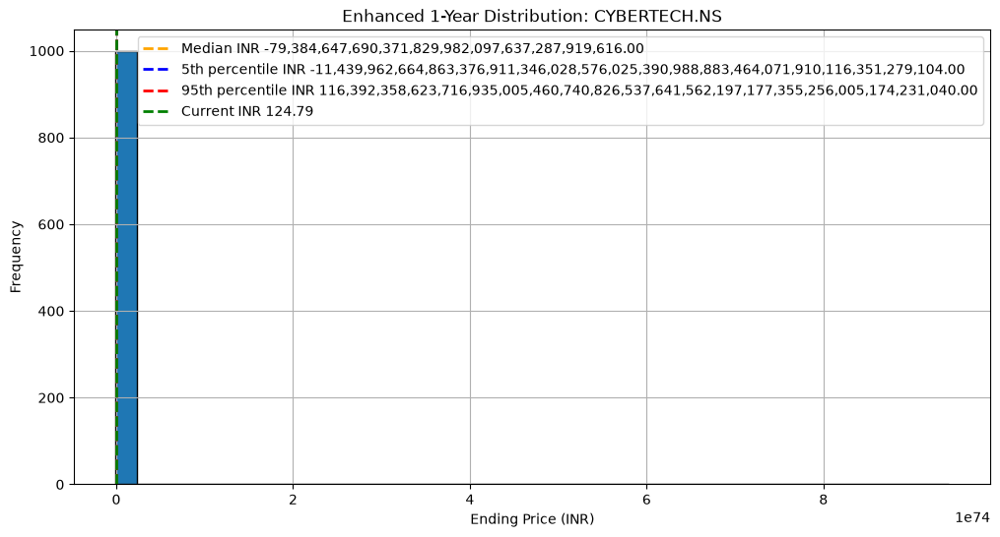

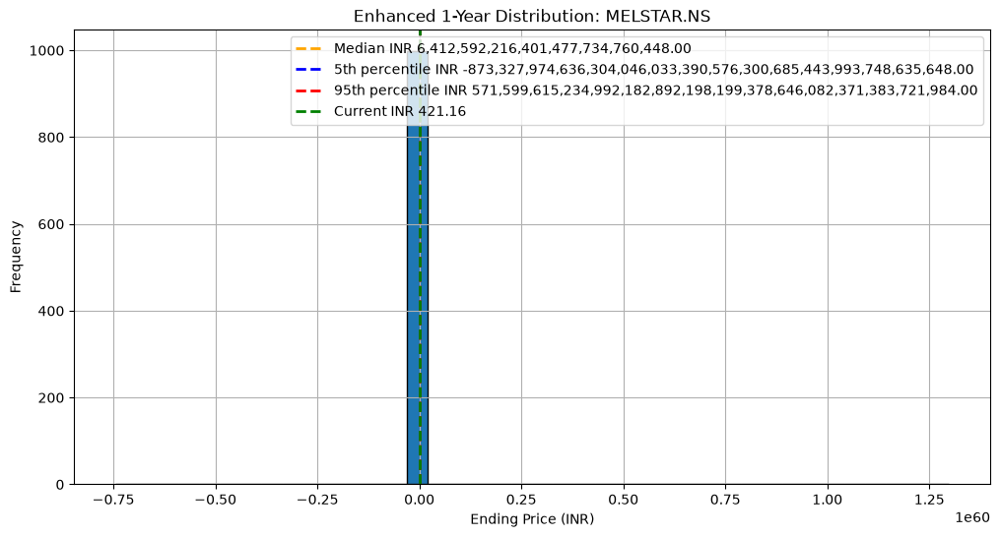

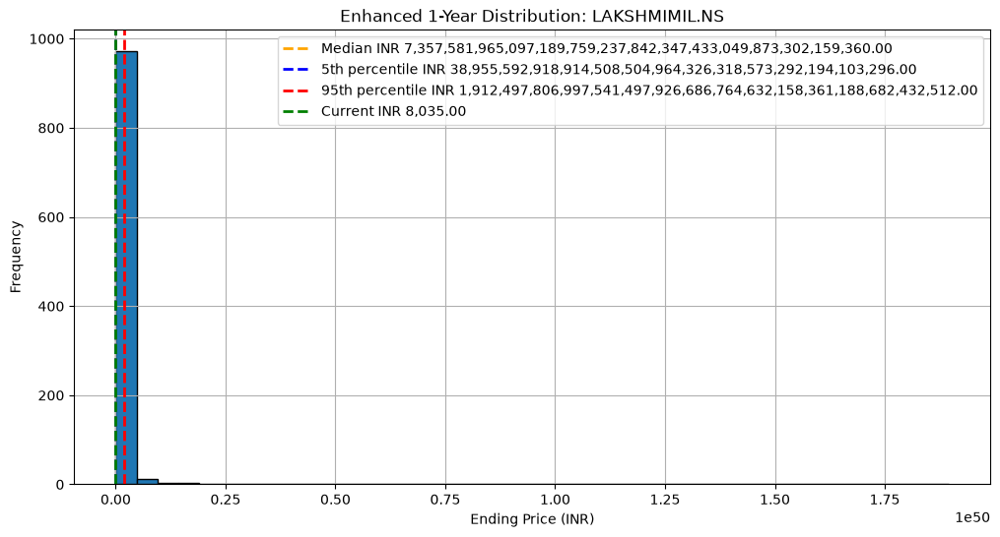

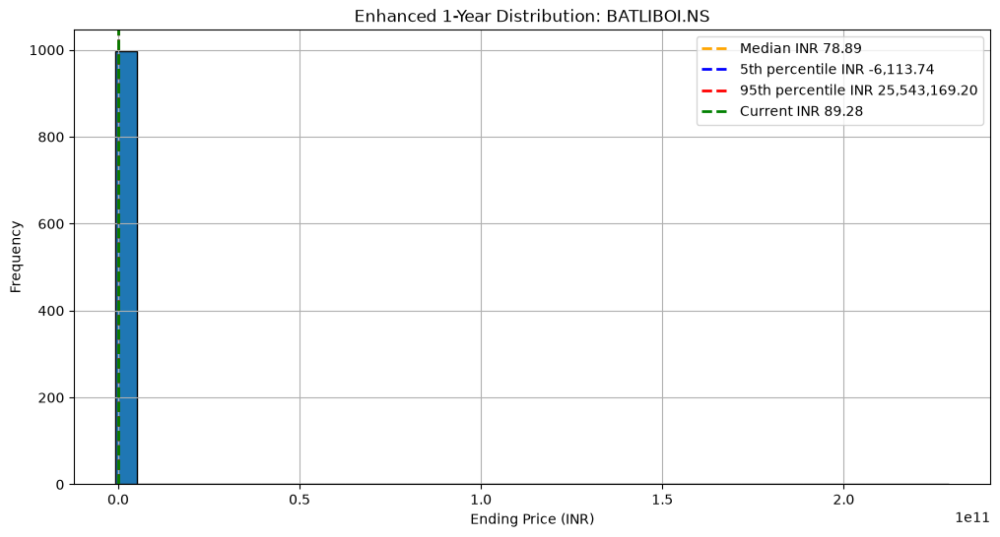

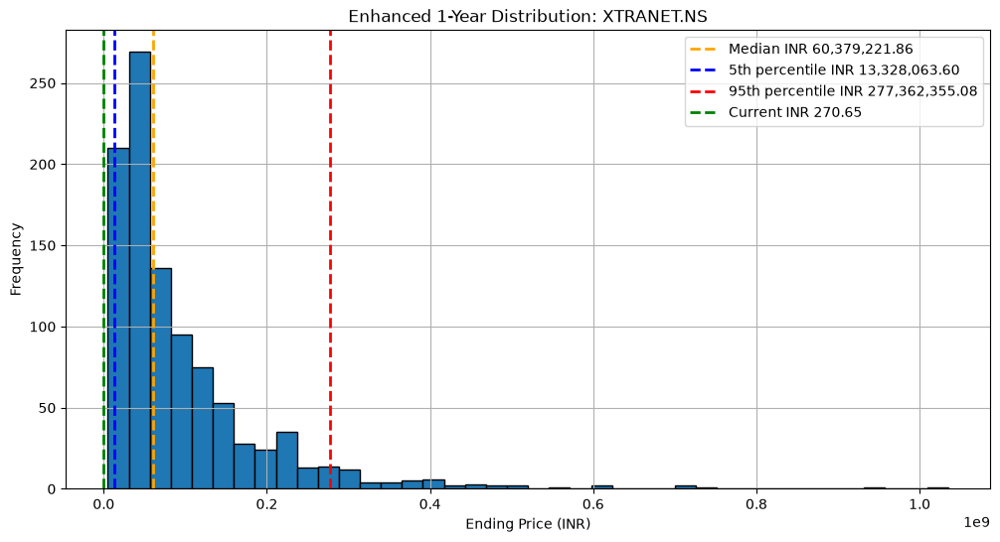

...

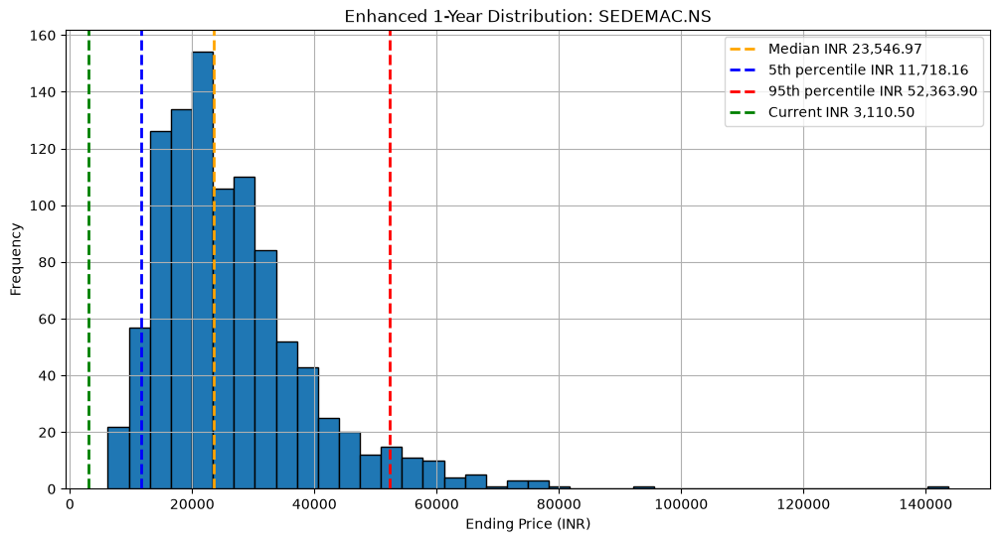

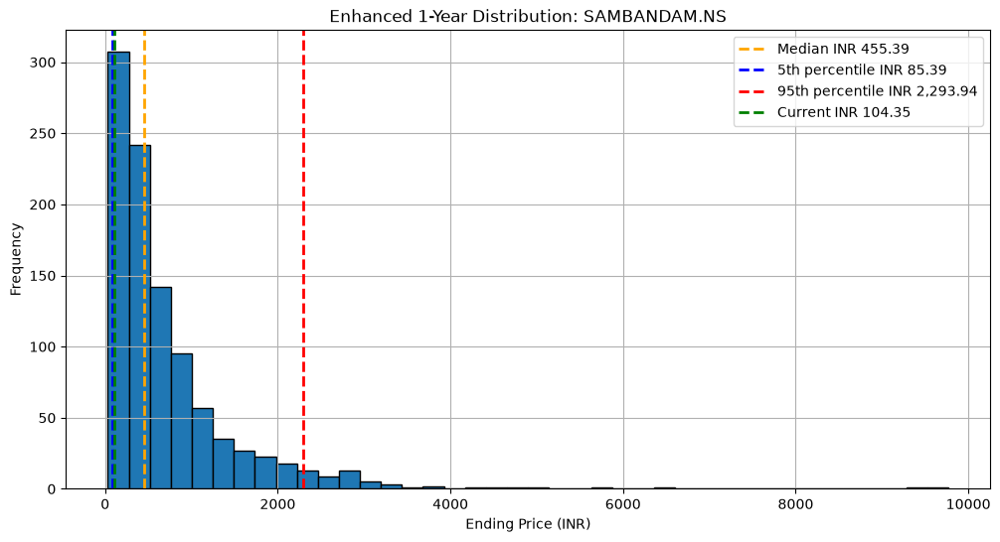

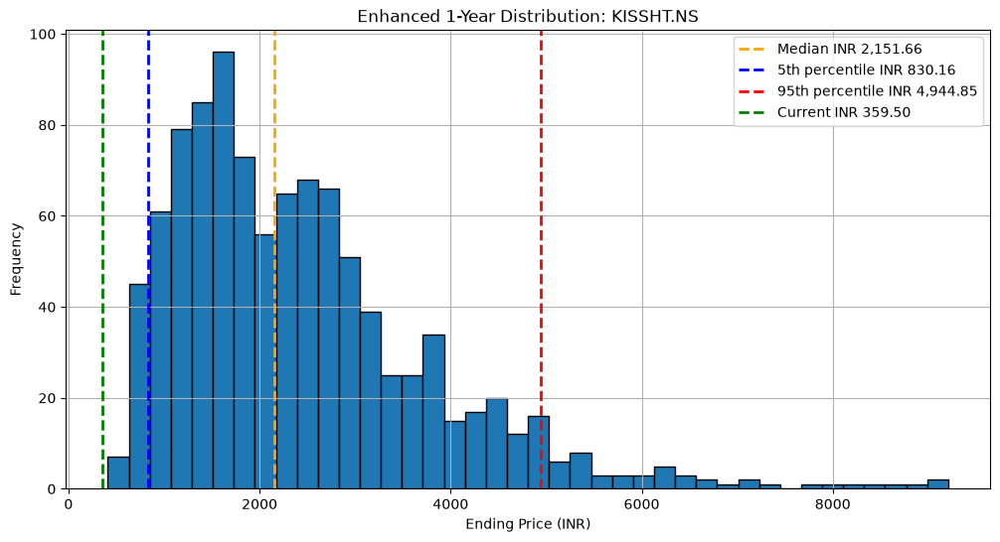

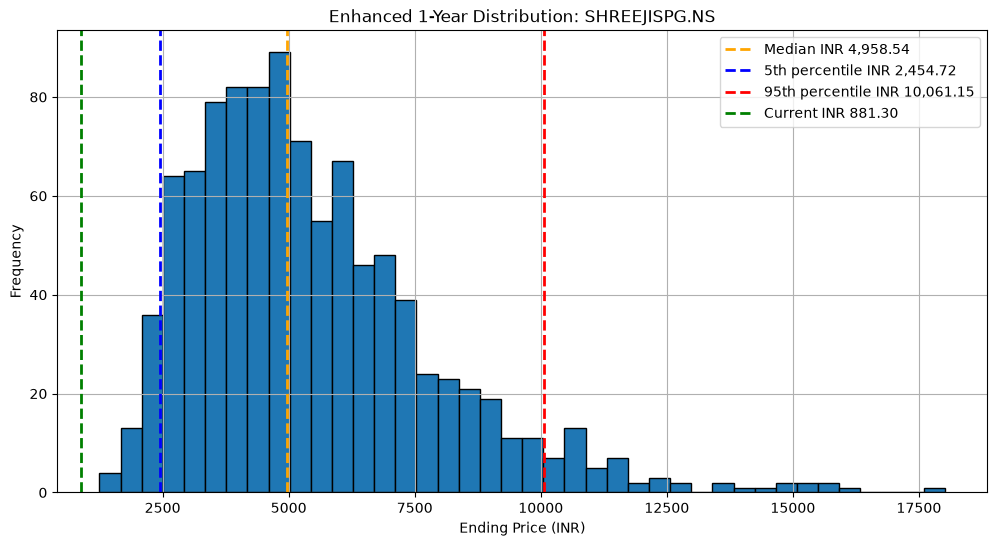

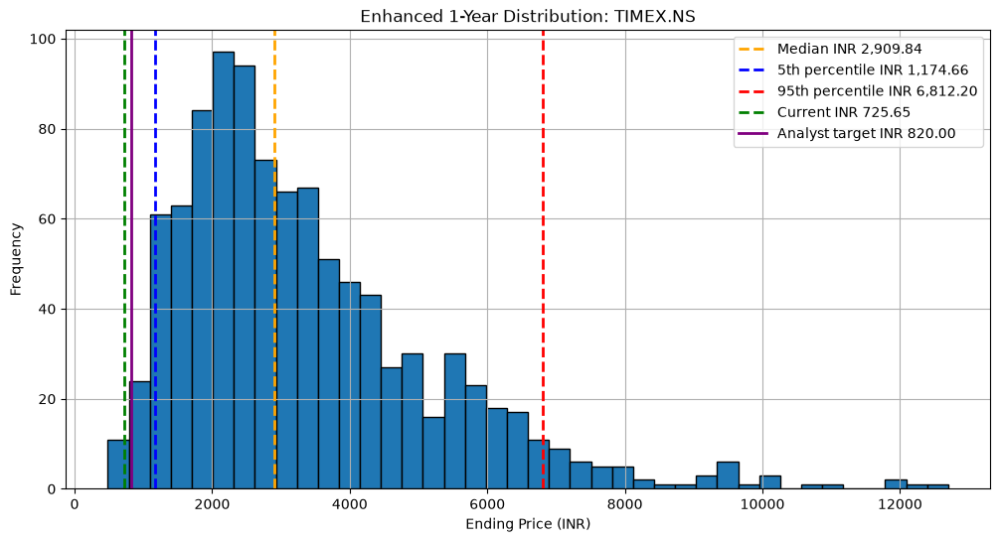

All enhanced results saved to nse_enhanced_simulation_data.pkl; plotted 20 symbols.


In [23]:
# Plot a small sample and save all enhanced NSE results together.
plot_candidates = enhanced_projection_table.sort_values('projected_return_pct', ascending=False).head(NSE_PLOT_LIMIT).index
for ticker_symbol in plot_candidates:
    prices = enhanced_simulation_results[ticker_symbol]
    summary = enhanced_projection_summary[ticker_symbol]
    plt.figure(figsize=(12, 6))
    plt.hist(prices, bins=40, edgecolor='black')
    plt.axvline(summary['p50'], color='orange', linestyle='dashed', linewidth=2, label=f"Median INR {summary['p50']:,.2f}")
    plt.axvline(summary['p5'], color='b', linestyle='dashed', linewidth=2, label=f"5th percentile INR {summary['p5']:,.2f}")
    plt.axvline(summary['p95'], color='r', linestyle='dashed', linewidth=2, label=f"95th percentile INR {summary['p95']:,.2f}")
    plt.axvline(summary['current_price'], color='g', linestyle='dashed', linewidth=2, label=f"Current INR {summary['current_price']:,.2f}")
    if summary['analyst_mean_1y'] is not None:
        plt.axvline(summary['analyst_mean_1y'], color='purple', linewidth=2, label=f"Analyst target INR {summary['analyst_mean_1y']:,.2f}")
    plt.xlabel('Ending Price (INR)')
    plt.ylabel('Frequency')
    plt.title(f'Enhanced 1-Year Distribution: {ticker_symbol}')
    plt.legend(); plt.grid(True)
    plt.savefig(f'histogram_enhanced_{ticker_symbol}.png')
    plt.show(); plt.close()
enhanced_saved_files = [f'histogram_enhanced_{t}.png' for t in plot_candidates]
enhanced_data_to_pickle = {
    'universe': stock_ticker, 'company_names': nse_company_names,
    'enhanced_simulation_results': enhanced_simulation_results,
    'projection_summary': enhanced_projection_summary, 'stock_metrics': stock_metrics,
    'fundamentals': fundamentals_by_ticker,
}
enhanced_pickle_path = 'nse_enhanced_simulation_data.pkl'
with open(enhanced_pickle_path, 'wb') as pickle_file:
    pickle.dump(enhanced_data_to_pickle, pickle_file)
print(f'All enhanced results saved to {enhanced_pickle_path}; plotted {len(enhanced_saved_files)} symbols.')


In [24]:
analyst_target_count = sum(s['analyst_mean_1y'] is not None for s in enhanced_projection_summary.values())
print(f'Enhanced projection coverage: {len(enhanced_projection_summary)} symbols.')
print(f'Analyst targets available for {analyst_target_count} symbols; others use historical CAGR.')
print(f"Median projected return: {enhanced_projection_table['projected_return_pct'].median():+.2f}%")


Enhanced projection coverage: 2355 symbols.
Analyst targets available for 142 symbols; others use historical CAGR.
Median projected return: +10.07%


# NSE Stock Screener - Top 15 by Projected 1-Year Return

Ranks downloaded NSE symbols with valid enhanced Monte Carlo results. Prices are in INR. Symbols without Yahoo price history are excluded; analyst enrichment is limited to `FUNDAMENTALS_TICKERS` to reduce rate-limit failures.


In [25]:
# Reuse the universe-wide simulation results; no extra downloads are needed.
nse_projection_table = enhanced_projection_table.sort_values('projected_return_pct', ascending=False).copy()
screener_columns = ['nse_symbol', 'company', 'current_price', 'mean_price', 'projected_return_pct', 'prob_gain', 'analyst_mean_1y']


In [26]:
print('TOP 15 NSE SYMBOLS BY PROJECTED 1-YEAR RETURN')
display(nse_projection_table[screener_columns].head(15).reset_index(drop=True))


TOP 15 NSE SYMBOLS BY PROJECTED 1-YEAR RETURN


,nse_symbol,company,current_price,mean_price,projected_return_pct,prob_gain,analyst_mean_1y
0,CYBERTECH,Cybertech Systems And Software Limited,124.790001,1.291829e+72,1.035202e+72,0.496,NaN
1,MELSTAR,Melstar Information Technologies Limited,421.160004,4.776472e+56,1.134123e+56,0.510,NaN
2,LAKSHMIMIL,Lakshmi Mills Company Limited,8035.000000,9.153938e+47,1.139258e+46,1.000,NaN
3,BATLIBOI,Batliboi Limited,89.279999,4.401783e+08,4.930312e+08,0.490,NaN
4,XTRANET,Xtranet Technologies Limited,270.649994,9.595976e+07,3.545520e+07,1.000,NaN
5,VTMLTD,VTM Limited,40.709999,1.920338e+05,4.716117e+05,0.997,NaN
6,AMARJOTHI,Amarjothi Spinning Mills Limited,152.500000,3.757333e+05,2.462825e+05,1.000,NaN
7,RAMBHAJO,Advit Jewels Limited,325.649994,2.228095e+04,6.741993e+03,1.000,NaN
8,RAJPALAYAM,Rajapalayam Mills Limited,751.200012,2.707358e+04,3.504044e+03,0.760,NaN
9,OMNI,Omnitech Engineering Limited,567.950012,1.775753e+04,3.026601e+03,1.000,NaN


In [27]:
print('BOTTOM 15 NSE SYMBOLS BY PROJECTED 1-YEAR RETURN')
display(nse_projection_table[screener_columns].tail(15).sort_values('projected_return_pct').reset_index(drop=True))


BOTTOM 15 NSE SYMBOLS BY PROJECTED 1-YEAR RETURN


,nse_symbol,company,current_price,mean_price,projected_return_pct,prob_gain,analyst_mean_1y
0,IMAGICAA,Imagicaaworld Entertainment Limited,43.410000,-1.264412e-03,-100.002913,0.000,NaN
1,GFLLIMITED,GFL Limited,54.080002,-2.585181e-06,-100.000005,0.000,NaN
2,ARIHANT,Arihant Foundations & Housing Limited,875.549988,1.300648e-07,-100.000000,0.000,NaN
3,EASTSILK,Eastern Silk Industries Limited,68.000000,2.744317e-02,-99.959642,0.000,NaN
4,GOODYEAR,Goodyear India Limited,693.849976,2.003445e+02,-71.125675,0.034,NaN
5,KSE,KSE Limited,173.440002,6.203406e+01,-64.233129,0.079,NaN
6,GRADIENTE,Gradiente Infotainment Limited,1.590000,6.133736e-01,-61.423043,0.023,NaN
7,AASTHA,Aastha Spintex Limited,25.790001,9.991736e+00,-61.257328,0.071,NaN
8,ALPINETEX,Alpine Texworld Limited,42.470001,1.701756e+01,-59.930394,0.021,NaN
9,TURTLEMINT,Turtlemint Fintech Solutions Limited,59.070000,2.385226e+01,-59.620349,0.051,NaN


In [28]:
nse_screen_csv_path = 'nse_stock_projection_screen.csv'
nse_projection_table[screener_columns].to_csv(nse_screen_csv_path, index=False)
print(f'Full NSE projection table saved to {nse_screen_csv_path}')


Full NSE projection table saved to nse_stock_projection_screen.csv


In [29]:
print(f'NSE symbols in selected official series: {len(nse_universe)}')
print(f'Symbols with downloaded price history: {len(stock_ticker)}')
print(f'Symbols with valid enhanced projections: {len(enhanced_projection_summary)}')
print(f'Analyst-enriched symbols: {analyst_target_count}')
print(f'Historical price data: {stock_name.index[0].date()} to {stock_name.index[-1].date()}.')


NSE symbols in selected official series: 2645
Symbols with downloaded price history: 2644
Symbols with valid enhanced projections: 2355
Analyst-enriched symbols: 142
Historical price data: 2009-01-02 to 2026-11-09.


In [32]:
positive_momentum_rows_with_forecast = []
for row in positive_momentum_rows:
    ticker_symbol = row['yahoo_ticker']
    metrics = stock_metrics.get(ticker_symbol, {})
    projection = enhanced_projection_summary.get(ticker_symbol, {})
    enriched_row = {key: value for key, value in row.items() if key != 'yahoo_ticker'}
    analyst_target = metrics.get('analyst_mean_1y')
    model_mean_price = projection.get('mean_price')
    enriched_row.update({
        'analyst_target_price_1y': analyst_target,
        'analyst_implied_return_pct_1y': (
            metrics['analyst_implied_return'] * 100
            if metrics.get('analyst_implied_return') is not None else None
        ),
        'analyst_opinions': fundamentals_by_ticker.get(ticker_symbol, {}).get('numberOfAnalystOpinions'),
        'analyst_recommendation': fundamentals_by_ticker.get(ticker_symbol, {}).get('recommendationKey'),
        'model_forecast_mean_price_1y': model_mean_price,
        'model_forecast_return_pct_1y': (
            (model_mean_price / row['current_price'] - 1) * 100
            if model_mean_price is not None and row['current_price'] > 0 else None
        ),
        'model_probability_gain_1y': projection.get('prob_gain'),
        'forecast_basis': (
            '50% historical CAGR + 50% analyst target-implied return'
            if analyst_target is not None else 'Historical CAGR; no analyst target available'
        ),
    })
    positive_momentum_rows_with_forecast.append(enriched_row)

positive_momentum_columns = [
    'nse_symbol', 'company', 'as_of', 'current_price',
    'model_forecast_mean_price_1y', 'analyst_target_price_1y',
    'model_forecast_return_pct_1y', 'analyst_implied_return_pct_1y',
    'ytd_return_pct', 'three_month_return_pct', 'ema_9', 'ema_20', 'ema_50',
    'analyst_opinions', 'analyst_recommendation',
    'model_probability_gain_1y', 'forecast_basis',
]
positive_momentum_table = pd.DataFrame(positive_momentum_rows_with_forecast, columns=positive_momentum_columns)
positive_momentum_table = positive_momentum_table[
    positive_momentum_table['model_forecast_return_pct_1y'] > 20
]
if not positive_momentum_table.empty:
    positive_momentum_table = positive_momentum_table.sort_values(
        ['ytd_return_pct', 'three_month_return_pct'], ascending=False
    ).reset_index(drop=True)

analyst_target_coverage = positive_momentum_table['analyst_target_price_1y'].notna().sum()
print(f'Stocks projected to gain more than 20% in the next year (among positive-momentum stocks): {len(positive_momentum_table)}')
print(f'Analyst targets available for {analyst_target_coverage} stocks in this filtered table.')
print('Analyst target-implied return and historical CAGR are blended 50/50 in the one-year model drift when a target is available.')
formatted_positive_momentum_table = positive_momentum_table.copy()
for price_column in ['current_price', 'model_forecast_mean_price_1y', 'analyst_target_price_1y']:
    formatted_positive_momentum_table[price_column] = formatted_positive_momentum_table[price_column].map(
        lambda price: f'{price:,.2f}' if pd.notna(price) else 'N/A'
    )
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(formatted_positive_momentum_table)


Stocks projected to gain more than 20% in the next year (among positive-momentum stocks): 119
Analyst targets available for 54 stocks in this filtered table.
Analyst target-implied return and historical CAGR are blended 50/50 in the one-year model drift when a target is available.


,nse_symbol,company,as_of,current_price,model_forecast_mean_price_1y,analyst_target_price_1y,model_forecast_return_pct_1y,analyst_implied_return_pct_1y,ytd_return_pct,three_month_return_pct,ema_9,ema_20,ema_50,analyst_opinions,analyst_recommendation,model_probability_gain_1y,forecast_basis
0,MELSTAR,Melstar Information Technologies Limited,2026-11-09,421.16,"477,647,214,303,761,346,417,318,835,546,135,84...",N/A,1.134123e+56,NaN,9809.647145,9809.647145,229.144963,128.680126,59.752783,NaN,none,0.510,Historical CAGR; no analyst target available
1,SIGMAADV,SIGMA ADVANCED SYSTEMS LIMITED,2026-11-09,937.95,"1,216.87",N/A,2.973736e+01,NaN,398.750412,33.811256,913.990798,913.562236,870.514288,NaN,none,0.566,Historical CAGR; no analyst target available
2,SPECTRUM,Spectrum Electrical Industries Limited,2026-11-09,"4,558.90","9,003.62",N/A,9.749553e+01,NaN,266.500508,86.786577,4204.518438,3977.917442,3502.085437,NaN,none,0.881,Historical CAGR; no analyst target available
3,CUPID,Cupid Limited,2026-11-09,342.85,643.76,N/A,8.776849e+01,NaN,230.872416,30.793881,335.739611,330.138294,308.236313,NaN,none,0.824,Historical CAGR; no analyst target available
4,MENONBE,Menon Bearings Limited,2026-11-09,342.95,445.89,N/A,3.001486e+01,NaN,220.693851,44.491259,317.696938,301.576069,284.924504,NaN,none,0.622,Historical CAGR; no analyst target available
5,NRL,Nupur Recyclers Limited,2026-11-09,169.30,236.36,N/A,3.960954e+01,NaN,198.694429,44.824637,166.225325,162.815788,150.614447,NaN,none,0.677,Historical CAGR; no analyst target available
6,CPPLUS,Aditya Infotech Limited,2026-11-09,"4,224.90","11,156.41","4,292.50",1.640633e+02,1.600040,183.493241,13.918623,4050.397113,3995.853774,3865.888899,6.0,strong_buy,0.972,50% historical CAGR + 50% analyst target-impli...
7,SSWL,Steel Strips Wheels Limited,2026-11-09,548.95,672.04,616.00,2.242222e+01,12.214225,183.402179,77.941657,520.096466,485.428635,424.556212,1.0,strong_buy,0.597,50% historical CAGR + 50% analyst target-impli...
8,SKYGOLD,SKY GOLD AND DIAMONDS LIMITED,2026-11-09,940.60,"2,391.51","1,185.67",1.542535e+02,26.054288,181.912181,30.747838,928.848152,924.137061,871.415418,3.0,strong_buy,0.910,50% historical CAGR + 50% analyst target-impli...
9,WHEELS,Wheels India Limited,2026-11-09,"2,387.50","3,035.24",N/A,2.713061e+01,NaN,177.519474,72.158921,2299.004476,2262.893950,2118.088282,NaN,none,0.628,Historical CAGR; no analyst target available
